In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import astropy.table as at
from astropy.table import Table
import astropy.units as u
import scipy

from cats.pawprint.pawprint import Pawprint
from cats.CMD import Isochrone
from cats.inputs import stream_inputs as inputs
from cats.proper_motions import ProperMotionSelection, rough_pm_poly
import cats.photometry as phot
from cats.data import make_astro_photo_joined_data

import galstreams as gst
from pyia import GaiaData
import gala.coordinates as gc

In [40]:
data_previous = Table.read("/Users/Tavangar/Work/gd1-dr3/data/GD1-region-alldata.fits")

In [43]:
mws = gst.MWStreams(verbose=False, implement_Off=True)

name = 'GD-1'
ms_name = 'GD-1-PB18'
g = GaiaData(f'/Users/Tavangar/Work/CATS_Workshop/data/GaiaDR3-{name}-all.fits')
p = phot.PS1Phot(f'/Users/Tavangar/Work/CATS_Workshop/data/PS1DR2-{name}_xm.fits')
gs = mws[ms_name]

Initializing galstreams library from master_log... 


In [44]:
stream_fr = gs.stream_frame

track = gs.track.transform_to(stream_fr)
if np.all(track.distance.value == 0):
    raise ValueError(
        "A distance track is required: this stream has no distance information in "
        "the galstreams track."
    )

# interpolator to get predicted distance from phi1
dist_interp = scipy.interpolate.InterpolatedUnivariateSpline(
    track.phi1.degree, track.distance.value, k=1
)

# get stream coordinates for all stars, and reflex correct with predicted distance
_c_tmp = g.get_skycoord(distance=False).transform_to(stream_fr)
c = g.get_skycoord(
    distance=dist_interp(_c_tmp.phi1.degree) * track.distance.unit,
    radial_velocity=0 * u.km / u.s,
)
c_stream = c.transform_to(stream_fr)
c_stream_refl = gc.reflex_correct(c_stream)

# start building the final joined table
gaia_data = g.data.copy()
for name in ["phi1", "phi2", "pm_phi1_cosphi2", "pm_phi2"]:
    gaia_data[name] = getattr(c_stream_refl, name)
    if name not in ["phi1", "phi2"]:
        gaia_data[f"{name}_unrefl"] = getattr(c_stream, name)

In [74]:
joined0 = at.join(gaia_data, p.data, keys="source_id")
joined = at.join(joined0, data_previous['source_id', 'rv', 'rv_err'], keys="source_id", join_type="left")

In [106]:
iso_obj.cat

source_id,ra,dec,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,ra_parallax_corr,ra_pmra_corr,ra_pmdec_corr,dec_parallax_corr,dec_pmra_corr,dec_pmdec_corr,parallax_pmra_corr,parallax_pmdec_corr,pmra_pmdec_corr,phot_g_mean_mag,phot_g_mean_flux_over_error,phot_bp_mean_mag,phot_bp_mean_flux_over_error,phot_rp_mean_mag,phot_rp_mean_flux_over_error,ruwe,astrometric_matched_transits,phi1,phi2,pm_phi1_cosphi2,pm1,pm_phi2,pm2,objID,raMean,decMean,nDetections,ng,nr,ni,nz,ny,gMeanPSFMag,rMeanPSFMag,iMeanPSFMag,zMeanPSFMag,yMeanPSFMag,gMeanPSFMagErr,rMeanPSFMagErr,iMeanPSFMagErr,zMeanPSFMagErr,yMeanPSFMagErr,g0,r0,i0,z0,y0,rv,rv_err
,,,,,,,,,,,,,,,,,,,,,,,,,,deg,deg,mas / yr,mas / yr,mas / yr,mas / yr,,,,,,,,,,,,,,,,,,,,,,,,,,
int64,float64,float64,float64,float32,float64,float32,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,int16,float64,float64,float64,float64,float64,float64,int64,float64,float64,int16,int16,int16,int16,int16,int16,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
576746900204578048,134.1785813868115,0.699903607168702,-0.387859966874895,1.0570223,0.8404360533051543,0.9320573,-2.5274593467993127,0.8070885,-0.20866951,-0.14958516,-0.0032666726,-0.02912248,0.02797563,-0.22435276,0.44840333,-0.20133851,-0.39092532,20.712267,136.26375,21.587004,5.5443625,19.724636,14.926739,0.93803054,31,-77.49584072316293,-7.957764488106117,3.727899676834207,-1.7628004209620283,1.059919717859738,-1.996726867970291,108841341786090362,134.17858075775126,0.6999064284561474,71,5,13,21,17,15,21.930999755859375,20.983699798583984,20.052799224853516,19.530000686645508,19.338600158691406,0.08505599945783615,0.02726300060749054,0.0137320002540946,0.028884999454021454,0.027481000870466232,21.782925978302956,20.877686068415642,19.974280908703804,19.468287717550993,19.287857346236706,--,--
576747007581207424,134.1937825126647,0.7203154579385792,0.44567563666171195,0.054363452,-8.233278145657213,0.05265684,3.3074368903596247,0.041687418,0.04580415,-0.008941007,0.012456373,0.0688402,0.044549335,-0.2622334,0.2989002,-0.04114594,-0.22885668,16.27391,2113.4995,16.61417,330.37082,15.770839,420.26526,0.99800134,51,-77.47030898715468,-7.9606474360557025,4.213325580614195,-1.278540705085957,11.836232641826392,8.780167508248732,108861341937984852,134.19378928334183,0.720313452993397,60,6,12,14,14,14,16.647600173950195,16.247499465942383,16.111400604248047,16.0846004486084,16.06439971923828,0.0018889999482780695,0.0018810000037774444,0.002495999913662672,0.0029959999956190586,0.004358999896794558,16.49972103536129,16.141625091433525,16.032985500991344,16.022968601435423,16.013723608106375,--,--
576747110659192064,134.19509489035744,0.7237244085353892,0.5420165918753204,0.046713714,-9.358144465692384,0.04782798,-8.430471717130894,0.03488169,0.08713422,-0.0050627645,-0.005285966,0.08358605,-0.0020849484,-0.26530662,0.15036698,-0.11948693,-0.08576689,15.866391,3007.8508,16.19205,537.6066,15.368745,486.4888,0.9832779,49,-77.46666723611173,-7.9600686333516135,-6.499638240022334,-11.991670738014033,6.909332373980188,3.853252408702399,108861341951078952,134.1951044836751,0.7237308700351704,54,6,10,10,16,12,16.224300384521484,15.850899696350098,15.713899612426758,15.679900169372559,15.659299850463867,0.0001900000061141327,0.003777999896556139,0.00559999980032444,0.0018420000560581684,0.008458999916911125,16.07642124593258,15.74502532184124,15.635484509170055,15.618268322199583,15.60862373933196,--,--
576747862277265408,134.1894707418727,0.7381690523969195,-2.7763415157065405,1.0521361,-2.938199452746094,1.082989,1.1067058314720313,0.97168803,-0.19492742,0.35428882,-0.14690888,-0.07634112,-0.032475024,0.09032123,-0.030825453,0.12878764,-0.3337938,20.69803,128.11299,20.864492,7.007613,19.731596,11.190689,0.98864704,32,-77.45691220525316,-7.947946950613543,4.972466947116149,-0.520

In [76]:
joined.write("/Users/Tavangar/Work/gd1-dr3/data/GD-1_all_data_2026.fits", overwrite=True)

In [99]:
stream_name = 'GD-1'
phi1_lim = (-100, 20)
pawprint = Pawprint.pawprint_from_galstreams(inputs[stream_name]['short_name'],
                                                 inputs[stream_name]['pawprint_id'],
                                                 width=inputs[stream_name]['width'] * u.deg,
                                                 phi1_lim=phi1_lim)

Modifying/extrapolating galstreams track
Modifying/extrapolating galstreams track


In [100]:
 # rough pm cut to start with (this comes only from the galstreams proper motion tracks)
pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, joined, buffer=2)

KeyError: 'pm_phi1_cosphi2_unrefl'

In [101]:
# Create the CMD cuts
iso_obj_ = Isochrone(joined, inputs[stream_name], pawprint=pawprint)
_, _, _, _, pprint = iso_obj_.simpleSln(mass_thresh=0.83)

KeyError: 'pm_phi1_cosphi2_unrefl'

-40.18182129005669
Fitting for peak pm location
Pre-fitting mean PM values: -13.031, -3.108
Post-fitting (pm1_mean, pm2_mean, pm1_std, pm2_std): [np.float64(-13.264440815567987), np.float64(-3.16520089374714), np.float64(0.40271098373675634), np.float64(0.5572649554286535)] 

Producing the polygon and mask


/Users/Tavangar/Work/CATS_Workshop/cats/cats/CMD.py:294: RuntimeWarning: invalid value encountered in divide
  signal = signal / signal_counts


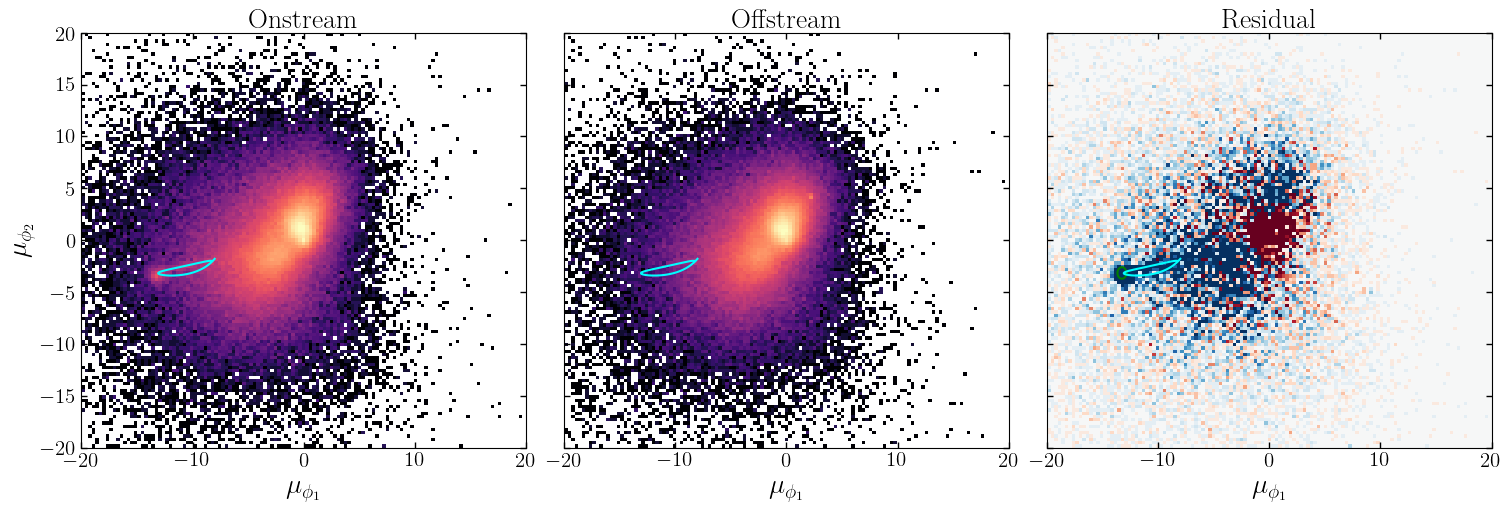

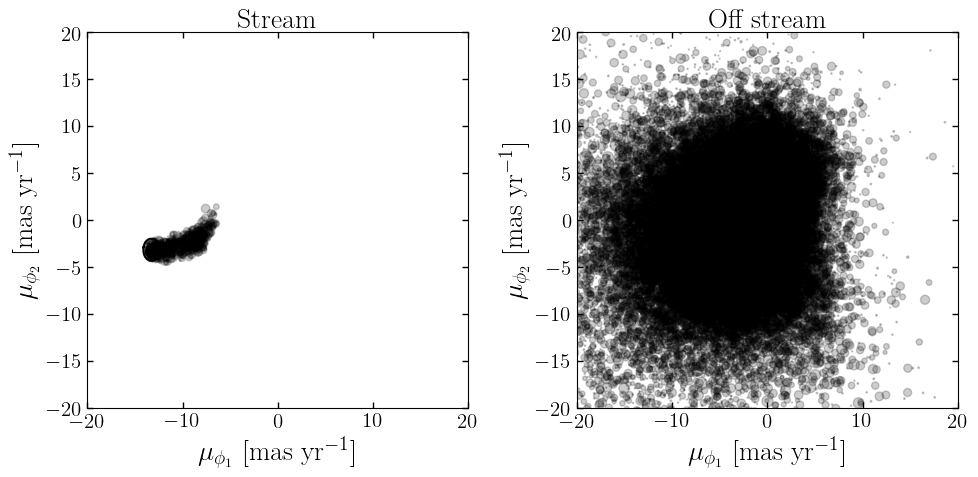

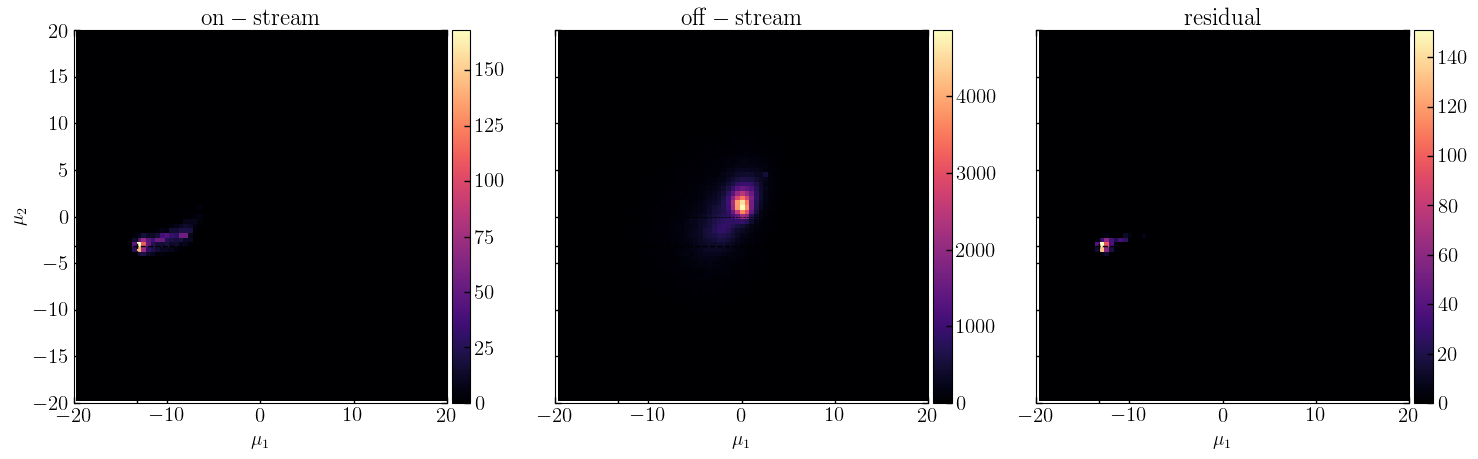

In [80]:
pmsel = ProperMotionSelection(joined, inputs[stream_name], pprint,
                                n_dispersion_phi1=3, n_dispersion_phi2=3, cutoff=0.1, plot=True)

iso_obj = Isochrone(joined, inputs[stream_name], pawprint=pmsel.pawprint,)
_, iso_mask, _, hb_mask, pprint = iso_obj.simpleSln(mass_thresh=0.83)

In [81]:
##### rough pm cut to start with (this comes only from the galstreams proper motion tracks)
pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, joined, buffer=2)

In [82]:
run_data_ = iso_obj.cat[pm_mask]# & (iso_mask | hb_mask)]
bkg_data_ = iso_obj.cat[pm_mask & ~iso_obj.on_skymask]
stream_data_ = iso_obj.cat[pmsel.pm12_mask & (iso_mask | hb_mask) & iso_obj.on_skymask]

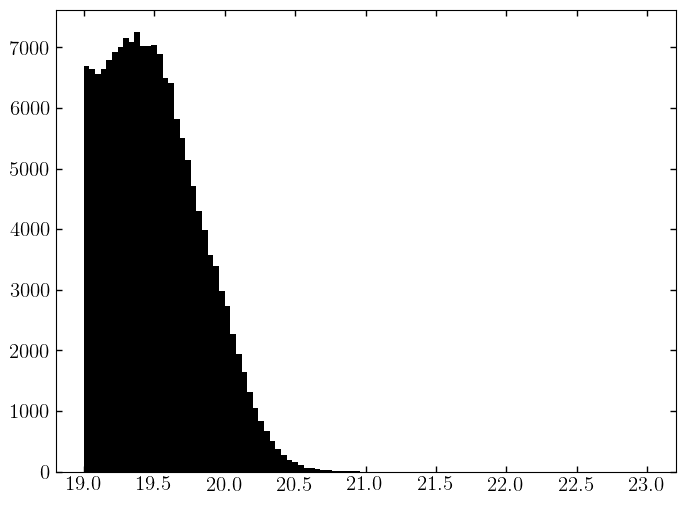

In [95]:
plt.hist(run_data_['phot_rp_mean_mag'], bins=100, range=[19,23])
plt.show()

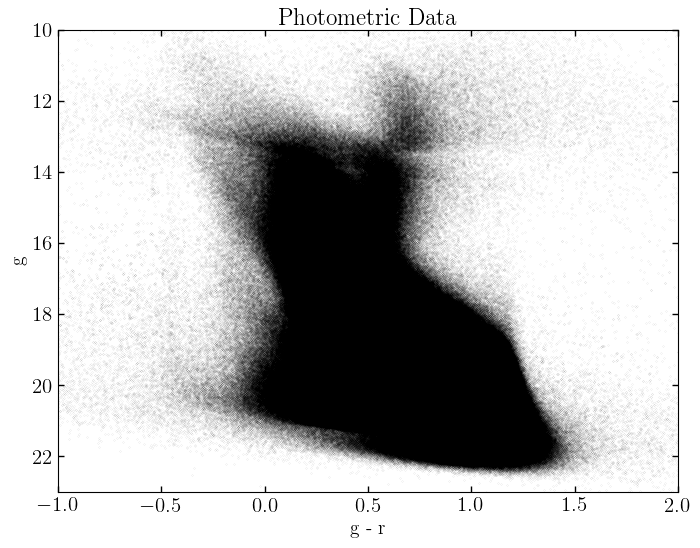

In [86]:
plt.scatter(joined['g0'] - joined['r0'], joined['g0'], s=0.001)
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.xlim(-1, 2); plt.ylim(23, 10)
plt.show()

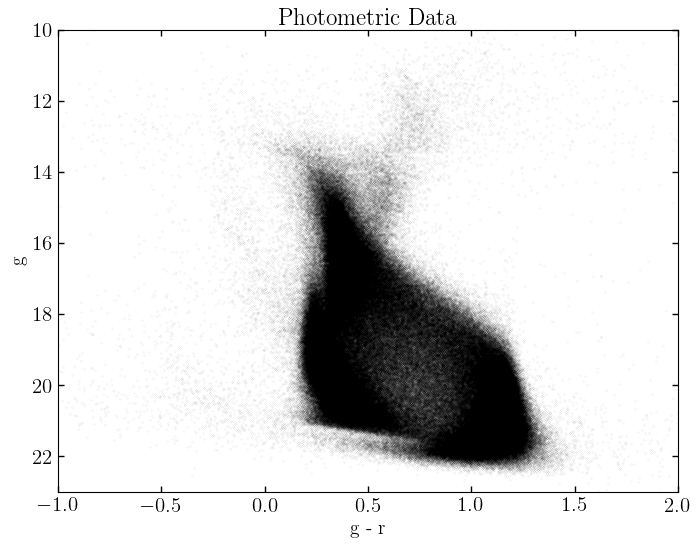

In [87]:
plt.scatter(run_data_['g0'] - run_data_['r0'], run_data_['g0'], s=0.001)
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.xlim(-1, 2); plt.ylim(23, 10)
plt.show()

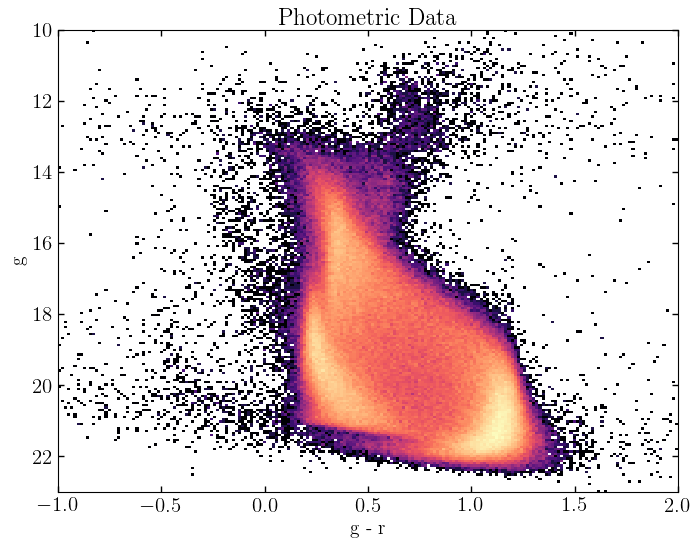

In [91]:
import matplotlib as mpl
plt.hist2d(bkg_data_['g0'] - bkg_data_['r0'], bkg_data_['g0'], bins=200, range=[[-1, 2], [10, 23]], norm=mpl.colors.LogNorm())
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.gca().invert_yaxis()
plt.show()

In [96]:
import pickle
post_cats = {'run_data': run_data_,
         'bkg_data': bkg_data_,
         'stream_data': stream_data_,
         'pawprint': pawprint,
         'iso_obj': iso_obj}
with open('../../data/post_cats_data_flow_version.pkl', 'wb') as param_file:
    pickle.dump(post_cats, param_file)
